<a href="https://colab.research.google.com/github/arjit-abhi/CVInsight/blob/main/01_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Setup & Data Ingestion

### Data Exploration — FSRS-Anki-20k
Start here: load the dataset, inspect columns, check size and basic stats.

In [ ]:
from huggingface_hub import login
# If running in Colab, uncomment to install deps:
# !pip install datasets huggingface_hub pandas -q

from datasets import load_dataset
import pandas as pd
from google.colab import userdata
from huggingface_hub import login

hf_token = userdata.get('HF_TOKEN')
login(token=hf_token)
ds = load_dataset("open-spaced-repetition/FSRS-Anki-20k", streaming=True)

sample = list(ds['train'].take(10000))
df = pd.DataFrame(sample)
print(df.shape)
df.head()

Resolving data files:   0%|          | 0/19999 [00:00<?, ?it/s]

(10000, 7)


,card_id,review_th,elapsed_days,elapsed_seconds,rating,state,duration
0,0,1,-1,-1,3,0,5737
1,0,2,0,5,3,1,5700
2,0,3,4,343517,3,2,60000
3,0,163,6,492673,4,2,60000
4,0,237,1,113476,2,4,36968


In [ ]:
# # Convert to pandas for easier exploration
# df = ds['train'].to_pandas() if 'train' in ds else ds[list(ds.keys())[0]].to_pandas()
# print(df.shape)
# df.head()

In [ ]:
# Basic checks
print(df.columns.tolist())
print(df.dtypes)
df.describe(include='all')

['card_id', 'review_th', 'elapsed_days', 'elapsed_seconds', 'rating', 'state', 'duration']
card_id            int64
review_th          int64
elapsed_days       int64
elapsed_seconds    int64
rating             int64
state              int64
duration           int64
dtype: object


,card_id,review_th,elapsed_days,elapsed_seconds,rating,state,duration
count,10000.000000,10000.00000,10000.000000,1.000000e+04,10000.000000,10000.000000,10000.000000
mean,329.922400,19871.31920,9.978800,8.721419e+05,2.324800,2.284200,25058.359100
std,191.945284,25860.02365,68.425869,5.910026e+06,0.943713,1.549474,24354.520779
min,0.000000,1.00000,-1.000000,-1.000000e+00,1.000000,0.000000,0.000000
25%,148.000000,2472.75000,0.000000,1.830000e+02,1.000000,1.000000,2674.750000
50%,357.000000,4972.50000,0.000000,9.246500e+03,3.000000,2.000000,13080.000000
75%,508.000000,45359.25000,1.000000,8.307125e+04,3.000000,4.000000,60000.000000
max,645.000000,105298.00000,1523.000000,1.315317e+08,4.000000,4.000000,60000.000000


In [ ]:
# Check for the response-latency column specifically (name may vary — confirm on load)
# e.g. df['duration'] — response time in ms
df['duration'].describe() if 'duration' in df.columns else print('check actual column name from df.columns above')

,duration
count,10000.000000
mean,25058.359100
std,24354.520779
min,0.000000
25%,2674.750000
50%,13080.000000
75%,60000.000000
max,60000.000000


## Next steps
- Confirm null/missing value patterns
- Check per-user review counts (some users may have very few reviews — cold-start noise)
- Move cleaning logic into `src/preprocessing.py` once stable, don't leave it only in this notebook

In [ ]:
"""
Baseline (HLR-style) vs latency-augmented recall prediction on FSRS-Anki-20k-style review logs.

Expected columns per user file:
    card_id, review_th, elapsed_days, elapsed_seconds, rating, state, duration
(rating: 1=again (failed recall), 2=hard, 3=good, 4=easy; duration in ms;
 elapsed_* = -1 for a card's first review.)

Design rules (see Methodology):
  * Target = recall success of a review (rating > 1), for review-state reviews with
    elapsed_days >= 1.
  * Features come ONLY from reviews BEFORE the target review, plus the elapsed time
    (known when the review happens). The target review's own duration is never used
    (it would leak the outcome).
  * Per-user chronological split; latency normalisation stats use the training period only.
"""
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.stats import wilcoxon
from sklearn.metrics import roc_auc_score

CAP_MS = 60_000          # Anki's default maximum answer time (right-censoring point)
LN2 = np.log(2.0)
ZMIN, ZMAX = -6.0, 9.0   # half-life between ~0.016 and ~512 days
EPS = 1e-6

BASE_FEATS = ["bias", "sqrt_right", "sqrt_wrong"]
LAT_FEATS = ["prev_z", "mean_z_before", "prev_capped"]


# ---------------------------------------------------------------- preprocessing
def prepare_user(df, min_targets=300, train_frac=0.7):
    """Build feature rows for one user. Returns None if the user has too few eligible reviews."""
    df = df[df["state"] != 4].copy()                      # drop filtered-deck reviews
    df = df.sort_values(["card_id", "review_th"]).reset_index(drop=True)

    df["success"] = (df["rating"] > 1).astype(int)
    df["log_dur"] = np.log(np.clip(df["duration"].astype(float), 1, CAP_MS))
    df["capped"] = (df["duration"] >= CAP_MS).astype(int)

    # eligible targets: review-state reviews with a previous review at least 1 day earlier
    elig = (df["state"] == 2) & (df["elapsed_days"] >= 1)
    if elig.sum() < min_targets:
        return None
    th_sorted = np.sort(df.loc[elig, "review_th"].values)
    cutoff = th_sorted[max(int(train_frac * len(th_sorted)) - 1, 0)]

    # per-user latency normalisation using the TRAINING period only
    train_mask = df["review_th"] <= cutoff
    mu = df.loc[train_mask, "log_dur"].mean()
    sd = max(df.loc[train_mask, "log_dur"].std(), 0.1)
    df["z"] = ((df["log_dur"] - mu) / sd).clip(-5, 5)

    g = df.groupby("card_id", sort=False)
    n_right = g["success"].cumsum() - df["success"]       # counts BEFORE this review
    n_wrong = g.cumcount() - n_right
    df["sqrt_right"] = np.sqrt(n_right)
    df["sqrt_wrong"] = np.sqrt(n_wrong)
    df["bias"] = 1.0

    prev_z = g["z"].shift(1)
    cnt = g.cumcount()
    mean_before = (g["z"].cumsum() - df["z"]) / cnt.replace(0, np.nan)
    df["prev_z"] = prev_z.fillna(0.0)
    df["mean_z_before"] = mean_before.fillna(0.0)
    df["prev_capped"] = g["capped"].shift(1).fillna(0.0)

    out = df.loc[elig].copy()
    out["y"] = out["success"]
    out["delta"] = np.maximum(out["elapsed_seconds"].astype(float) / 86400.0, 1e-3)
    out["split"] = np.where(out["review_th"] <= cutoff, "train", "test")
    keep = ["card_id", "review_th", "y", "delta", "split"] + BASE_FEATS + LAT_FEATS
    return out[keep].reset_index(drop=True)


# ---------------------------------------------------------------- HLR-style model
def _loss_grad(theta, X, delta, y, l2):
    z_raw = X @ theta
    z = np.clip(z_raw, ZMIN, ZMAX)
    u = LN2 * delta * np.exp(-LN2 * z)                    # u = ln2 * delta / h, h = 2^z
    p = np.clip(np.exp(-u), EPS, 1 - EPS)                 # p = 2^(-delta/h)
    reg = l2 * np.sum(theta[1:] ** 2)
    loss = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)) + reg
    dz = (-y + (1 - y) * p / (1 - p)) * LN2 * u
    dz = dz * ((z_raw > ZMIN) & (z_raw < ZMAX))
    grad = X.T @ dz / len(y)
    grad[1:] += 2 * l2 * theta[1:]
    return loss, grad


def fit_hlr(X, delta, y, l2=1e-3):
    theta0 = np.zeros(X.shape[1])
    theta0[0] = np.log2(5.0)                              # start at a 5-day half-life
    res = minimize(_loss_grad, theta0, args=(X, delta, y, l2), jac=True, method="L-BFGS-B")
    return res.x


def predict_hlr(theta, X, delta):
    z = np.clip(X @ theta, ZMIN, ZMAX)
    return np.clip(2.0 ** (-delta / (2.0 ** z)), EPS, 1 - EPS)


# ---------------------------------------------------------------- metrics
def logloss(y, p):
    p = np.clip(p, EPS, 1 - EPS)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))


def ece(y, p, bins=10):
    idx = np.minimum((p * bins).astype(int), bins - 1)
    total, n = 0.0, len(y)
    for b in range(bins):
        m = idx == b
        if m.any():
            total += m.sum() / n * abs(y[m].mean() - p[m].mean())
    return float(total)


def per_user_metrics(test_df, p, users):
    rows = []
    for u in np.unique(users):
        m = users == u
        y = test_df["y"].values[m]
        row = {"user": u, "n": int(m.sum()), "logloss": logloss(y, p[m])}
        row["auc"] = roc_auc_score(y, p[m]) if (len(np.unique(y)) == 2 and m.sum() >= 30) else np.nan
        rows.append(row)
    return pd.DataFrame(rows)


# ---------------------------------------------------------------- experiment
def run_experiment(user_frames, l2=1e-3):
    """user_frames: dict user_id -> output of prepare_user (None already removed)."""
    parts = []
    for uid, f in user_frames.items():
        f = f.copy()
        f["user"] = uid
        parts.append(f)
    tr, te = pd.concat(parts, ignore_index=True)[pd.concat(parts, ignore_index=True).split == "train"], pd.concat(parts, ignore_index=True)[pd.concat(parts, ignore_index=True).split == "test"]

    models = {
        "HLR (baseline)": BASE_FEATS,
        "HLR + latency": BASE_FEATS + LAT_FEATS,
    }
    results, preds, thetas = [], {}, {}

    # trivial reference: each user's training recall rate
    base_rate = tr.groupby("user")["y"].mean()
    p_rate = te["user"].map(base_rate).clip(EPS, 1 - EPS).values
    preds["User base rate"] = p_rate

    for name, feats in models.items():
        theta = fit_hlr(tr[feats].values, tr["delta"].values, tr["y"].values, l2)
        thetas[name] = dict(zip(feats, np.round(theta, 4)))
        preds[name] = predict_hlr(theta, te[feats].values, te["delta"].values)

    y = te["y"].values
    for name, p in preds.items():
        results.append({
            "model": name,
            "AUC (pooled)": roc_auc_score(y, p) if name != "User base rate" else roc_auc_score(y, p),
            "log loss": logloss(y, p),
            "ECE": ece(y, p),
        })
    summary = pd.DataFrame(results).set_index("model")

    # paired per-user comparison (baseline vs latency)
    pu_b = per_user_metrics(te, preds["HLR (baseline)"], te["user"].values).set_index("user")
    pu_l = per_user_metrics(te, preds["HLR + latency"], te["user"].values).set_index("user")
    paired = pd.DataFrame({
        "logloss_base": pu_b["logloss"], "logloss_lat": pu_l["logloss"],
        "auc_base": pu_b["auc"], "auc_lat": pu_l["auc"], "n_test": pu_b["n"],
    })
    tests = {}
    d_ll = (paired["logloss_base"] - paired["logloss_lat"]).dropna()   # >0 means latency better
    if len(d_ll) >= 5 and (d_ll != 0).any():
        tests["logloss_wilcoxon_p"] = wilcoxon(d_ll).pvalue
    d_auc = (paired["auc_lat"] - paired["auc_base"]).dropna()          # >0 means latency better
    if len(d_auc) >= 5 and (d_auc != 0).any():
        tests["auc_wilcoxon_p"] = wilcoxon(d_auc).pvalue
    tests["users_latency_better_logloss"] = int((d_ll > 0).sum())
    tests["users_total"] = int(len(d_ll))
    return summary, paired, thetas, tests, pd.concat(parts, ignore_index=True)

In [ ]:
f = prepare_user(df, min_targets=200)
print(None if f is None else f.shape)
summary, paired, thetas, tests, data = run_experiment({0: f})
display(summary.round(4))
print(thetas)

(1195, 11)


,AUC (pooled),log loss,ECE
model,,,
User base rate,0.5000,0.2236,0.0097
HLR (baseline),0.5807,0.4822,0.0831
HLR + latency,0.5716,0.4214,0.0794


{'HLR (baseline)': {'bias': np.float64(6.2648), 'sqrt_right': np.float64(2.4004), 'sqrt_wrong': np.float64(-3.0124)}, 'HLR + latency': {'bias': np.float64(6.9451), 'sqrt_right': np.float64(1.9607), 'sqrt_wrong': np.float64(-2.666), 'prev_z': np.float64(-0.93), 'mean_z_before': np.float64(-0.4817), 'prev_capped': np.float64(0.0082)}}


## DHP-HLR Baseline Model & Out-of-Sample Evaluation

In [ ]:
!git clone -q https://github.com/maimemo/SSP-MMC-Plus.git
!apt-get -qq install p7zip-full

fatal: destination path 'SSP-MMC-Plus' already exists and is not an empty directory.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np

# Point directly to your mounted Google Drive Dataset folder
path = '/content/drive/MyDrive/Dataset/opensource_dataset_forgetting_curve.tsv'
df = pd.read_csv(path, sep="\t")

print("Original shape:", df.shape)
print(df.head(3))

Original shape: (71699, 7)
   d  i t_history r_history  delta_t  p_recall  total_cnt
0  1  3       0,1       0,1        4    0.8284        134
1  1  3       0,1       0,1        6    0.8649       6871
2  1  3       0,2       0,0        1    0.8395      21946


Load and Filter

In [ ]:
import numpy as np, pandas as pd

# Updated path pointing to your Google Drive Dataset folder
path = "/content/drive/MyDrive/Dataset/opensource_dataset_forgetting_curve.tsv"

data = pd.read_csv(path, sep="\t")
print("raw rows:", len(data))
data = data[(data["p_recall"] < 1) & (data["p_recall"] > 0)].copy()
print("after dropping p_recall of 0 or 1:", len(data))

raw rows: 71699
after dropping p_recall of 0 or 1: 71696


Half-life of each group

In [ ]:
keys = ["d", "i", "r_history", "t_history"]
data["_a"] = data["delta_t"] * np.log(data["p_recall"]) * data["total_cnt"]
data["_b"] = (data["delta_t"] ** 2) * data["total_cnt"]
grp = data.groupby(keys)
a = grp["_a"].transform("sum")
b = grp["_b"].transform("sum")
data["halflife"] = np.where(data["i"] > 1, np.round(np.log(0.5) * b / a, 4), 0.0)
data["group_cnt"] = grp["total_cnt"].transform("sum")
data = data.drop(columns=["_a", "_b"])
data["p_recall"] = data["p_recall"].map(lambda x: round(x, 2))
print(data["halflife"].describe())

count    71696.000000
mean        52.623865
std         91.904827
min          0.349100
25%          6.653775
50%         20.818800
75%         58.328750
max       2397.100700
Name: halflife, dtype: float64


Build the recall-probability history

In [ ]:
data = data.sort_values("i", kind="stable").reset_index(drop=True)
data["p_history"] = "0"
data["last_halflife"] = np.nan
data["last_p_recall"] = np.nan

d2p = [0.86, 0.78, 0.72, 0.66, 0.61, 0.55, 0.49, 0.44, 0.39, 0.34]

m = data["i"] == 2
data.loc[m, "p_history"] = data.loc[m, "d"].map(lambda d: str(d2p[d - 1]))

for lvl in range(3, int(data["i"].max()) + 1):
    kids = data[data["i"] == lvl][["d", "t_history", "r_history"]].copy()
    if kids.empty:
        continue
    t_split = kids["t_history"].str.rsplit(",", n=1, expand=True)
    r_split = kids["r_history"].str.rsplit(",", n=1, expand=True)
    kids["par_t"] = t_split[0]
    kids["par_dt"] = t_split[1].astype(int)
    kids["par_r"] = r_split[0]

    par = data[data["i"] == lvl - 1][["d", "t_history", "r_history", "delta_t", "p_history", "p_recall", "halflife"]]
    par = par.rename(columns={"t_history": "par_t", "r_history": "par_r", "delta_t": "par_dt",
                              "p_history": "par_ph", "p_recall": "par_p", "halflife": "par_h"})
    assert not par.duplicated(["d", "par_t", "par_r", "par_dt"]).any(), "duplicate parent rows"

    kids = kids.reset_index().merge(par, on=["d", "par_t", "par_r", "par_dt"], how="left").set_index("index")
    kids = kids[kids["par_ph"].notna()]
    data.loc[kids.index, "p_history"] = kids["par_ph"] + "," + kids["par_p"].astype(str)
    data.loc[kids.index, "last_halflife"] = kids["par_h"]
    data.loc[kids.index, "last_p_recall"] = kids["par_p"]

checks and save

In [ ]:
ok = (data["p_history"].str.count(",") == data["t_history"].str.count(","))
print("rows where p_history lines up with t_history:", ok.sum(), "of", len(data))

row = data[(data.d == 1) & (data.t_history == "0,1") & (data.r_history == "0,1") & (data.delta_t == 3)]
print(row[["d","i","t_history","r_history","p_history","delta_t","p_recall","total_cnt","halflife","last_halflife","last_p_recall"]].to_string())

data.to_csv("/content/drive/MyDrive/Dataset/opensource_dataset_p_history.tsv", sep="\t", index=False)

rows where p_history lines up with t_history: 66207 of 71696
    d  i t_history r_history  p_history  delta_t  p_recall  total_cnt  halflife  last_halflife  last_p_recall
61  1  3       0,1       0,1  0.86,0.88        3      0.94     548832   33.3114         6.2884           0.88


Evaluation

In [ ]:
import numpy as np, pandas as pd, math, torch
from sklearn.model_selection import RepeatedKFold

path = "/content/drive/MyDrive/Dataset/opensource_dataset_p_history.tsv"
df = pd.read_csv(path, sep="\t")
for c in ["r_history", "t_history", "p_history"]:
    df[c] = df[c].astype(str)

df = df[(df["halflife"] > 0) & (df["i"] > 0)]
df = df[df["p_history"].str.count(",") == df["t_history"].str.count(",")].reset_index(drop=True)
print("usable samples:", len(df))

df["r_list"] = df["r_history"].map(lambda s: [int(float(x)) for x in s.split(",")])
df["t_list"] = df["t_history"].map(lambda s: [float(x) for x in s.split(",")])
df["p_list"] = df["p_history"].map(lambda s: [float(x) for x in s.split(",")])
assert (df.r_list.map(len) == df.t_list.map(len)).all()
assert (df.p_list.map(len) == df.t_list.map(len)).all()

pool = df.sample(frac=0.8, random_state=2022)      # 80%: cross-validation
tune = df.drop(pool.index)                         # 20%: tuning
folds = list(RepeatedKFold(n_splits=2, n_repeats=5, random_state=2022).split(pool))
print("pool:", len(pool), "tune:", len(tune), "folds:", len(folds))

def smape(F, A):
    F, A = np.asarray(F, float), np.asarray(A, float)
    return float(np.mean(2 * np.abs(F - A) / (np.abs(A) + np.abs(F))))

def evaluate(sub, h_hat):
    h_hat = np.asarray(h_hat, float)
    p_hat = np.power(2.0, -sub["delta_t"].values / h_hat)
    return {"MAE_p": float(np.mean(np.abs(p_hat - sub["p_recall"].values))),
            "sMAPE_h": smape(h_hat, sub["halflife"].values)}

# sanity checks
print(df[["d", "i", "t_list", "r_list", "p_list", "delta_t", "p_recall", "halflife"]].head(3).to_string())
print("oracle (true half-life):", evaluate(df, df["halflife"].values))

usable samples: 66207
pool: 52966 tune: 13241 folds: 10
   d  i t_list r_list  p_list  delta_t  p_recall  halflife
0  2  2  [0.0]    [0]  [0.78]        3      0.69    3.6342
1  3  2  [0.0]    [0]  [0.72]        2      0.66    2.7063
2  5  2  [0.0]    [0]  [0.61]        1      0.67    1.7598
oracle (true half-life): {'MAE_p': 0.004131016024889638, 'sMAPE_h': 0.0}


In [ ]:
!grep -n -i -E "leitner|pimsleur|right|wrong|sqrt|def feature_extract|def hclip|def pclip|MIN_HALF|MAX_HALF|lrate|hlwt|l2wt|sigma|n_iter" /content/SSP-MMC-Plus/model/halflife_regression.py
!echo "------ train_baseline.py ------"
!grep -n -i -E "leitner|pimsleur|right|wrong|halflife_regression|n_iter|omit|random_state|KFold|split" /content/SSP-MMC-Plus/train_baseline.py

2:Copyright (c) 2016 Duolingo Inc. MIT Licence.
23:MIN_HALF_LIFE = 15.0 / (24 * 60)  # 15 minutes
24:MAX_HALF_LIFE = 274. * 100  # 9 months
28:Instance = namedtuple('Instance', 'p t fv h a right wrong spelling'.split())
36:      - 'leitner' (fixed)
37:      - 'pimsleur' (fixed)
41:                 lrate=.001, hlwt=.002,
42:                 l2wt=.001, sigma=1.):
50:        self.lrate = lrate
51:        self.hlwt = hlwt
52:        self.l2wt = l2wt
53:        self.sigma = sigma
58:        self.n_iter = 7500000
59:        self.n_epoch = int(self.n_iter / self.trainset_cnt + 1)
68:                ('right', 2.6457513110645907), 
69:                ('wrong', 2.0), 
76:            return MAX_HALF_LIFE
83:        elif self.method == 'leitner':
87:                h = MAX_HALF_LIFE
90:        elif self.method == 'pimsleur':
94:                h = MAX_HALF_LIFE
106:                s = - MAX_HALF_LIFE * math.log(0.9) / LN2
120:                rate = (1. / (1 + inst.p)) * self.lrate / math.sqrt(1 + 

In [ ]:
!ls /content/SSP-MMC-Plus
!echo "------ lines 60-100 ------"
!sed -n '60,100p' /content/SSP-MMC-Plus/model/halflife_regression.py
!echo "------ lines 255-295 ------"
!sed -n '255,295p' /content/SSP-MMC-Plus/model/halflife_regression.py
!echo "------ where right/wrong come from ------"
!grep -rn "wrong" /content/SSP-MMC-Plus --include=*.py | grep -v "model/halflife_regression.py"

analysis.py    evaluate.py  preprocess.py  SSP-MMC
CITATION.cff   LICENSE	    README.md	   train.py
envrioment.py  model	    simulator.py   visualization.py
------ lines 60-100 ------
        self.cur_iter = 0
        random.seed(2022)

    def halflife(self, inst, base):
        try:
            dp = sum([self.weights[k] * x_k for (k, x_k) in inst.fv])
            """
            fv=[
                ('right', 2.6457513110645907), 
                ('wrong', 2.0), 
                ('bias', 1.0), 
                ('es:hago/hacer<vblex><pri><p1><sg>', 1.0)
            ]
            """
            return hclip(base ** dp)
        except:
            return MAX_HALF_LIFE

    def predict(self, inst, base=2.):
        if self.method == 'HLR':
            h = self.halflife(inst, base)
            p = 2. ** (-inst.t / h)
            return pclip(p), h
        elif self.method == 'leitner':
            try:
                h = hclip(2. ** inst.fv[0][1])
            except OverflowError:
     

In [ ]:
!sed -n '1,130p' /content/SSP-MMC-Plus/train.py

import argparse
import random
import sys
import numpy as np
import pandas as pd
import math
from collections import namedtuple
from sklearn.model_selection import KFold, train_test_split, RepeatedKFold

Instance = namedtuple('Instance', 'p t fv h a r_history t_history p_history'.split())
duolingo_algo = ('HLR', 'LR', 'leitner', 'pimsleur')
rnn_algo = ('GRU', 'RNN', 'LSTM')


def load_data(input_file):
    dataset = pd.read_csv(input_file, sep='\t', index_col=None)
    dataset = dataset[dataset['halflife'] > 0]
    dataset = dataset[dataset['i'] > 0]
    dataset = dataset[
        dataset['p_history'].map(lambda x: len(str(x).split(','))) == dataset['t_history'].map(lambda x: len(x.split(',')))]
    # dataset.drop_duplicates(subset=['r_history', 't_history', 'p_history', 'difficulty'], inplace=True)
    # dataset['weight'] = dataset['total_cnt'] / dataset['total_cnt'].sum()
    # dataset['weight'] = dataset['total_cnt'] / dataset['total_cnt'].sum()
    # std = preprocessing.MinMaxScaler

In [ ]:
!sed -n '15,75p' /content/SSP-MMC-Plus/train.py

def load_data(input_file):
    dataset = pd.read_csv(input_file, sep='\t', index_col=None)
    dataset = dataset[dataset['halflife'] > 0]
    dataset = dataset[dataset['i'] > 0]
    dataset = dataset[
        dataset['p_history'].map(lambda x: len(str(x).split(','))) == dataset['t_history'].map(lambda x: len(x.split(',')))]
    # dataset.drop_duplicates(subset=['r_history', 't_history', 'p_history', 'difficulty'], inplace=True)
    # dataset['weight'] = dataset['total_cnt'] / dataset['total_cnt'].sum()
    # dataset['weight'] = dataset['total_cnt'] / dataset['total_cnt'].sum()
    # std = preprocessing.MinMaxScaler()
    # dataset['weight_std'] = std.fit_transform(dataset[['weight']]) + 1
    dataset['weight_std'] = 1
    return dataset


def feature_extract(train_set, test_set, method, omit_lexemes=False):
    instances = {'train': [], 'test': []}
    for set_id, data in (('train', train_set), ('test', test_set)):
        for i, row in data.iterrows():
            p = float(row['p_rec

Define helper feature

In [ ]:
import sys, math
sys.path.insert(0, "/content/SSP-MMC-Plus")
from model.halflife_regression import SpacedRepetitionModel, Instance

def feature_extract(train_set, test_set, method, omit_lexemes=False):
    out = {"train": [], "test": []}
    for set_id, data in (("train", train_set), ("test", test_set)):
        for _, row in data.iterrows():
            p = float(row["p_recall"]); t = max(1, int(row["delta_t"])); h = float(row["halflife"])
            right = row["r_history"].count("1"); wrong = row["r_history"].count("0"); total = right + wrong
            fv = []
            if method == "pimsleur":
                fv.append((sys.intern("total"), total))
            elif method == "leitner":
                fv.append((sys.intern("diff"), right - wrong))
            else:
                fv.append((sys.intern("right"), math.sqrt(1 + right)))
                fv.append((sys.intern("wrong"), math.sqrt(1 + wrong)))
            if not omit_lexemes:
                fv.append((sys.intern(str(row["d"])), 1.0))
            fv.append((sys.intern("bias"), 1.0))
            out[set_id].append(Instance(p, t, fv, h, (right + 2.0) / (total + 4.0),
                                        row["r_history"], row["t_history"], row["p_history"]))
    return out["train"], out["test"]

def run_baselines(train, test, quick_iters=1_000_000):
    res = {}
    for name, method, omit_l in [("Leitner", "leitner", True), ("Pimsleur", "pimsleur", True),
                                 ("HLR", "HLR", False), ("HLR -l", "HLR", True)]:
        tr, te = feature_extract(train, test, method, omit_l)
        m = SpacedRepetitionModel(tr, te, method=method)
        if method == "HLR":
            if quick_iters:
                m.n_iter = quick_iters
                m.n_epoch = int(m.n_iter / m.trainset_cnt + 1)
            m.train()
        h_hat = [m.predict(inst)[1] for inst in te]
        res[name] = evaluate(test, h_hat)
        print(name, "done", res[name])
    return res

In [ ]:
tr0, te0 = folds[0]
r = run_baselines(pool.iloc[tr0], pool.iloc[te0])
print(pd.DataFrame(r).T.round(4))

Leitner done {'MAE_p': 0.40435393410085707, 'sMAPE_h': 1.2885331135519758}
Pimsleur done {'MAE_p': 0.28807339634844276, 'sMAPE_h': 1.7214231326618148}


test	132415	481517.5 (p=6311.3, h=475206.1, l2=0.0)	mae(p)=0.402	cor(p)=-0.058	mae(h)=42.318	cor(h)=0.051
test	264830	423204.1 (p=1958.3, h=421245.8, l2=0.0)	mae(p)=0.190	cor(p)=-0.050	mae(h)=36.842	cor(h)=0.089
test	397245	379773.7 (p=1140.3, h=378633.4, l2=0.0)	mae(p)=0.153	cor(p)=-0.060	mae(h)=40.447	cor(h)=0.144
test	529660	373336.1 (p=1080.6, h=372255.5, l2=0.0)	mae(p)=0.149	cor(p)=-0.038	mae(h)=39.773	cor(h)=0.184
test	662075	368318.8 (p=1032.1, h=367286.7, l2=0.0)	mae(p)=0.146	cor(p)=-0.018	mae(h)=39.373	cor(h)=0.211
test	794490	364300.8 (p=996.1, h=363304.6, l2=0.0)	mae(p)=0.144	cor(p)=0.001	mae(h)=38.863	cor(h)=0.233
test	926905	360967.8 (p=966.6, h=360001.2, l2=0.0)	mae(p)=0.142	cor(p)=0.018	mae(h)=38.391	cor(h)=0.250


HLR done {'MAE_p': 0.14112773768968837, 'sMAPE_h': 0.911242529947946}


test	132415	482642.4 (p=6540.5, h=476101.8, l2=0.0)	mae(p)=0.411	cor(p)=-0.060	mae(h)=42.467	cor(h)=0.051
test	264830	433139.1 (p=2260.9, h=430878.2, l2=0.0)	mae(p)=0.205	cor(p)=-0.045	mae(h)=37.331	cor(h)=0.085
test	397245	382513.9 (p=1174.9, h=381339.0, l2=0.0)	mae(p)=0.154	cor(p)=-0.069	mae(h)=40.457	cor(h)=0.131
test	529660	377913.1 (p=1128.8, h=376784.2, l2=0.0)	mae(p)=0.152	cor(p)=-0.052	mae(h)=39.860	cor(h)=0.161
test	662075	374436.7 (p=1090.7, h=373346.0, l2=0.0)	mae(p)=0.149	cor(p)=-0.038	mae(h)=39.484	cor(h)=0.183
test	794490	371717.8 (p=1062.7, h=370655.1, l2=0.0)	mae(p)=0.147	cor(p)=-0.024	mae(h)=39.018	cor(h)=0.199
test	926905	369495.3 (p=1038.8, h=368456.5, l2=0.0)	mae(p)=0.146	cor(p)=-0.012	mae(h)=38.616	cor(h)=0.212


HLR -l done {'MAE_p': 0.14496077963627563, 'sMAPE_h': 0.9133029747660422}
           MAE_p  sMAPE_h
Leitner   0.4044   1.2885
Pimsleur  0.2881   1.7214
HLR       0.1411   0.9112
HLR -l    0.1450   0.9133


In [ ]:
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence

Lmax = int(df["i"].max()) - 1
Xnp = np.zeros((len(df), Lmax, 3), np.float32); lens = np.zeros(len(df), np.int64)
for k, (rl, tl, pl) in enumerate(zip(df["r_list"], df["t_list"], df["p_list"])):
    L = len(rl); Xnp[k, :L, 0] = rl; Xnp[k, :L, 1] = tl; Xnp[k, :L, 2] = pl; lens[k] = L
XT, LT = torch.tensor(Xnp), torch.tensor(lens)
HT = torch.tensor(df["halflife"].values, dtype=torch.float32)

# channels per step: 0 = outcome r, 1 = interval t, 2 = earlier recall probability p
VARIANTS = {"GRU-HLR": [0, 1, 2], "GRU-HLR -p": [0, 1], "GRU-HLR -t": [0, 2], "GRU-HLR -p -t": [0]}

class GRUHLR(nn.Module):
    def __init__(self, n_in, n_hidden=2):
        super().__init__()
        self.gru = nn.GRU(n_in, n_hidden, num_layers=1, batch_first=True)
        self.fc = nn.Linear(n_hidden, 1)
    def forward(self, x, lens):
        packed = pack_padded_sequence(x, lens, batch_first=True, enforce_sorted=False)
        _, hn = self.gru(packed)
        return torch.exp(self.fc(hn[-1])).squeeze(-1)

def smape_loss(F, A):
    return torch.mean(2 * torch.abs(F - A) / (torch.abs(F) + torch.abs(A)))

def gru_predict(model, ids, chans, bs=2048):
    model.eval(); out = []
    with torch.no_grad():
        for b in range(0, len(ids), bs):
            bi = torch.tensor(ids[b:b + bs])
            out.append(model(XT[bi][:, :, chans], LT[bi]).numpy())
    return np.concatenate(out)

def train_gru(ids, chans, n_hidden=2, epochs=30, bs=64, lr=1e-3, wd=1e-5, seed=0, watch=False):
    torch.manual_seed(seed); rng = np.random.RandomState(seed)
    model = GRUHLR(len(chans), n_hidden)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    for ep in range(epochs):
        model.train(); perm = rng.permutation(ids); tot = 0.0
        for b in range(0, len(perm), bs):
            bi = torch.tensor(perm[b:b + bs])
            loss = smape_loss(model(XT[bi][:, :, chans], LT[bi]), HT[bi])
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(bi)
        if watch and (ep + 1) % 10 == 0:
            print(f"  epoch {ep+1}: train sMAPE(h)={tot/len(perm):.4f} | tune set:",
                  {k: round(v, 4) for k, v in evaluate(tune, gru_predict(model, tune.index.values, chans)).items()})
    return model

In [ ]:
!pip install -q sympy==1.13.1

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.2/6.2 MB 17.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.11.0+cpu requires sympy>=1.13.3, but you have sympy 1.13.1 which is incompatible.


In [ ]:
import time
SEEDS = [0]          # first run: one seed; add 1 and 2 only if this is fast enough
EPOCHS = 100
tr0, te0 = folds[0]
train0, test0 = pool.iloc[tr0], pool.iloc[te0]

rows = []
for name, ch in VARIANTS.items():
    for s in SEEDS:
        t0 = time.time()
        model = train_gru(train0.index.values, ch, epochs=EPOCHS, seed=s)
        m = evaluate(test0, gru_predict(model, test0.index.values, ch))
        rows.append({"model": name, "seed": s, "MAE_p": m["MAE_p"], "sMAPE_h": m["sMAPE_h"]})
        print(name, "seed", s, {k: round(v, 4) for k, v in m.items()}, f"({(time.time()-t0)/60:.1f} min)")
res_long = pd.DataFrame(rows)
print(res_long.groupby("model")[["MAE_p", "sMAPE_h"]].mean().round(4))

GRU-HLR seed 0 {'MAE_p': 0.0315, 'sMAPE_h': 0.1968} (5.6 min)
GRU-HLR -p seed 0 {'MAE_p': 0.0316, 'sMAPE_h': 0.2021} (5.4 min)
GRU-HLR -t seed 0 {'MAE_p': 0.034, 'sMAPE_h': 0.2121} (5.4 min)
GRU-HLR -p -t seed 0 {'MAE_p': 0.0378, 'sMAPE_h': 0.2316} (5.5 min)
                MAE_p  sMAPE_h
model                         
GRU-HLR        0.0315   0.1968
GRU-HLR -p     0.0316   0.2021
GRU-HLR -p -t  0.0378   0.2316
GRU-HLR -t     0.0340   0.2121


In [ ]:
final = res_long.set_index("model")[["MAE_p", "sMAPE_h"]].copy()
final.loc["DHP-HLR"] = [0.0806, 0.4883]
final.loc["HLR (1M updates)"] = [0.1411, 0.9112]
final.loc["Pimsleur"] = [0.2881, 1.7214]
final.loc["Leitner"] = [0.4044, 1.2885]
final["MAE(p) cut vs HLR"] = (1 - final["MAE_p"] / 0.1411).round(3)
print(final.round(4))
final.round(4).to_csv("/content/drive/MyDrive/Dataset/reproduction_results_fold0.csv")

                   MAE_p  sMAPE_h  MAE(p) cut vs HLR
model                                               
GRU-HLR           0.0315   0.1968              0.777
GRU-HLR -p        0.0316   0.2021              0.776
GRU-HLR -t        0.0340   0.2121              0.759
GRU-HLR -p -t     0.0378   0.2316              0.732
DHP-HLR           0.0806   0.4883              0.429
HLR (1M updates)  0.1411   0.9112              0.000
Pimsleur          0.2881   1.7214             -1.042
Leitner           0.4044   1.2885             -1.866


DHP-HLR

In [ ]:
from sklearn.linear_model import LinearRegression

def start_h(d):
    return -1.0 / math.log2(max(0.925 - 0.05 * d, 0.025))

def fit_dhp(train):
    t = train.drop_duplicates(subset=["d", "i", "r_history", "t_history"])
    t = t[t["i"] > 2].dropna(subset=["last_halflife", "last_p_recall"]).copy()
    last_r = t["r_history"].str[-1]
    n0 = t["r_history"].str.count("0")
    ratio = (t["halflife"] / t["last_halflife"]).values
    with np.errstate(all="ignore"):
        X = np.column_stack([np.log(t["d"].values.astype(float)),
                             np.log(t["last_halflife"].values),
                             np.log(1 - t["last_p_recall"].values)])
    finite = np.isfinite(X).all(axis=1)
    rec = ((last_r == "1") & (n0 == 1)).values & (ratio > 1) & finite
    fgt = ((last_r == "0") & (n0 == 2)).values & finite
    m_rec = LinearRegression().fit(X[rec], np.log(ratio[rec] - 1))
    m_fgt = LinearRegression().fit(X[fgt], np.log(t["halflife"].values[fgt]))
    print("recall rows:", int(rec.sum()), "| forget rows:", int(fgt.sum()),
          "| dropped as non-finite:", int((~finite).sum()))
    return {"ra": m_rec.intercept_, "rb": m_rec.coef_[0], "rc": m_rec.coef_[1], "rd": m_rec.coef_[2],
            "fa": m_fgt.intercept_, "fb": m_fgt.coef_[0], "fc": m_fgt.coef_[1], "fd": m_fgt.coef_[2]}

def predict_dhp(sub, q):
    out = []
    for d0, rl, tl in zip(sub["d"], sub["r_list"], sub["t_list"]):
        d = float(d0); h = start_h(d)
        for r, t in zip(rl, tl):
            if t == 0:
                h = start_h(d); continue
            p = min(2.0 ** (-t / h), 1 - 1e-12)
            if r == 1:
                h = h * (1 + math.exp(q["ra"]) * d ** q["rb"] * h ** q["rc"] * (1 - p) ** q["rd"])
            else:
                h = math.exp(q["fa"]) * d ** q["fb"] * h ** q["fc"] * (1 - p) ** q["fd"]
                d = min(d + 2, 18)
        out.append(h)
    return np.array(out)

In [ ]:
# Check 1: coefficients on all usable data vs the paper's
q_all = fit_dhp(df)
print({k: round(v, 3) for k, v in q_all.items()})
print("paper:  recall (3.25, -0.386, -0.147, 0.821)   forget (1.003, -0.152, 0.264, -0.017)")

# Check 2: fold 0 metrics (fit on the training half, test on the other half)
tr0, te0 = folds[0]
q0 = fit_dhp(pool.iloc[tr0])
h_hat = predict_dhp(pool.iloc[te0], q0)
print("non-finite predictions:", int((~np.isfinite(h_hat)).sum()))
print("DHP-HLR fold 0:", evaluate(pool.iloc[te0], h_hat))
print("HLR fold 0 (from Step 3): MAE_p 0.1411, sMAPE_h 0.9112")

recall rows: 902 | forget rows: 777 | dropped as non-finite: 0
{'ra': np.float64(3.252), 'rb': np.float64(-0.386), 'rc': np.float64(-0.147), 'rd': np.float64(0.821), 'fa': np.float64(1.003), 'fb': np.float64(-0.152), 'fc': np.float64(0.265), 'fd': np.float64(-0.017)}
paper:  recall (3.25, -0.386, -0.147, 0.821)   forget (1.003, -0.152, 0.264, -0.017)
recall rows: 610 | forget rows: 361 | dropped as non-finite: 0
non-finite predictions: 0
DHP-HLR fold 0: {'MAE_p': 0.08055516725335017, 'sMAPE_h': 0.48826057342732115}
HLR fold 0 (from Step 3): MAE_p 0.1411, sMAPE_h 0.9112


In [ ]:
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence

Lmax = int(df["i"].max()) - 1
Xnp = np.zeros((len(df), Lmax, 3), np.float32); lens = np.zeros(len(df), np.int64)
for k, (rl, tl, pl) in enumerate(zip(df["r_list"], df["t_list"], df["p_list"])):
    L = len(rl); Xnp[k, :L, 0] = rl; Xnp[k, :L, 1] = tl; Xnp[k, :L, 2] = pl; lens[k] = L
XT, LT = torch.tensor(Xnp), torch.tensor(lens)
HT = torch.tensor(df["halflife"].values, dtype=torch.float32)

# channels per step: 0 = outcome r, 1 = interval t, 2 = earlier recall probability p
VARIANTS = {"GRU-HLR": [0, 1, 2], "GRU-HLR -p": [0, 1], "GRU-HLR -t": [0, 2], "GRU-HLR -p -t": [0]}

class GRUHLR(nn.Module):
    def __init__(self, n_in, n_hidden=2):
        super().__init__()
        self.gru = nn.GRU(n_in, n_hidden, num_layers=1, batch_first=True)
        self.fc = nn.Linear(n_hidden, 1)
    def forward(self, x, lens):
        packed = pack_padded_sequence(x, lens, batch_first=True, enforce_sorted=False)
        _, hn = self.gru(packed)
        return torch.exp(self.fc(hn[-1])).squeeze(-1)

def smape_loss(F, A):
    return torch.mean(2 * torch.abs(F - A) / (torch.abs(F) + torch.abs(A)))

def gru_predict(model, ids, chans, bs=2048):
    model.eval(); out = []
    with torch.no_grad():
        for b in range(0, len(ids), bs):
            bi = torch.tensor(ids[b:b + bs])
            out.append(model(XT[bi][:, :, chans], LT[bi]).numpy())
    return np.concatenate(out)

def train_gru(ids, chans, n_hidden=2, epochs=30, bs=64, lr=1e-3, wd=1e-5, seed=0, watch=False):
    torch.manual_seed(seed); rng = np.random.RandomState(seed)
    model = GRUHLR(len(chans), n_hidden)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    for ep in range(epochs):
        model.train(); perm = rng.permutation(ids); tot = 0.0
        for b in range(0, len(perm), bs):
            bi = torch.tensor(perm[b:b + bs])
            loss = smape_loss(model(XT[bi][:, :, chans], LT[bi]), HT[bi])
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(bi)
        if watch and (ep + 1) % 10 == 0:
            print(f"  epoch {ep+1}: train sMAPE(h)={tot/len(perm):.4f} | tune set:",
                  {k: round(v, 4) for k, v in evaluate(tune, gru_predict(model, tune.index.values, chans)).items()})
    return model

In [ ]:
tr0, te0 = folds[0]
train0, test0 = pool.iloc[tr0], pool.iloc[te0]

gru_res = {}
for name, ch in VARIANTS.items():
    print("training", name, "...")
    model = train_gru(train0.index.values, ch, epochs=30, watch=(name == "GRU-HLR"))
    gru_res[name] = evaluate(test0, gru_predict(model, test0.index.values, ch))
    print(name, {k: round(v, 4) for k, v in gru_res[name].items()})

gru_res["DHP-HLR"] = {"MAE_p": 0.0806, "sMAPE_h": 0.4883}
gru_res["HLR (quick)"] = {"MAE_p": 0.1411, "sMAPE_h": 0.9112}
print(pd.DataFrame(gru_res).T.round(4))

training GRU-HLR ...
  epoch 10: train sMAPE(h)=0.2447 | tune set: {'MAE_p': 0.0414, 'sMAPE_h': 0.2463}
  epoch 20: train sMAPE(h)=0.2216 | tune set: {'MAE_p': 0.0352, 'sMAPE_h': 0.2192}
  epoch 30: train sMAPE(h)=0.2159 | tune set: {'MAE_p': 0.0351, 'sMAPE_h': 0.2163}
GRU-HLR {'MAE_p': 0.0353, 'sMAPE_h': 0.2159}
training GRU-HLR -p ...
GRU-HLR -p {'MAE_p': 0.0329, 'sMAPE_h': 0.2124}
training GRU-HLR -t ...
GRU-HLR -t {'MAE_p': 0.0365, 'sMAPE_h': 0.2247}
training GRU-HLR -p -t ...
GRU-HLR -p -t {'MAE_p': 0.0386, 'sMAPE_h': 0.2358}
                MAE_p  sMAPE_h
GRU-HLR        0.0353   0.2159
GRU-HLR -p     0.0329   0.2124
GRU-HLR -t     0.0365   0.2247
GRU-HLR -p -t  0.0386   0.2358
DHP-HLR        0.0806   0.4883
HLR (quick)    0.1411   0.9112


In [ ]:
# import pandas as pd
# import numpy as np
# from scipy.optimize import minimize

# # Load the processed history dataset from Drive
# path = "/content/drive/MyDrive/Dataset/opensource_dataset_p_history.tsv"
# df = pd.read_csv(path, sep="\t")

# print("Loaded history dataset shape:", df.shape)
# print(df.head(2))

Loaded history dataset shape: (71696, 12)
   d  i t_history r_history  delta_t  p_recall  total_cnt  halflife  \
0  2  2         0         0        3      0.69        789    3.6342   
1  3  2         0         0        2      0.66      22625    2.7063   

   group_cnt p_history  last_halflife  last_p_recall  
0    1460641      0.75            NaN            NaN  
1    2187501      0.72            NaN            NaN  


GRU-HLR

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np

# Check device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"using device: {device}")

# 1. Prepare sequential tensors from your history dataset
class MemoryDataset(torch.utils.data.Dataset):
    def __init__(self, df):
        self.deltas = torch.tensor(df['delta_t'].values, dtype=torch.float32).unsqueeze(1)
        self.p_actuals = torch.tensor(df['p_recall'].values, dtype=torch.float32).unsqueeze(1)

        # Target halflife calculated previously
        p_clipped = np.clip(df['p_recall'].values, 0.001, 0.999)
        h_target = -df['delta_t'].values / np.log2(p_clipped)
        self.h_targets = torch.tensor(h_target, dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return len(self.deltas)

    def __getitem__(self, idx):
        return self.deltas[idx], self.p_actuals[idx], self.h_targets[idx]

dataset = MemoryDataset(df)
dataloader = torch.utils.data.DataLoader(dataset, batch_size=64, shuffle=True)

# 2. Define GRU-HLR Architecture (Paper Section III-D)
class GRUHLRModel(nn.Module):
    def __init__(self, input_dim=2, hidden_dim=16):
        super(GRUHLRModel, self).__init__()
        self.gru = nn.GRU(input_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        out, hidden = self.gru(x)
        log_h_pred = self.fc(out[:, -1, :])
        h_pred = torch.pow(2.0, log_h_pred)
        return h_pred

model = GRUHLRModel().to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)

# Symmetric Mean Absolute Percentage Error (SMAPE) loss as specified in Eq. 12 of the paper
def smape_loss(h_pred, h_true):
    return torch.mean(torch.abs(h_pred - h_true) / (torch.abs(h_pred) + torch.abs(h_true) + 1e-6))

# 3. Training Loop
print("Training GRU-HLR model...")
model.train()
for epoch in range(5):
    total_loss = 0.0
    for deltas, p_acts, h_true in dataloader:
        deltas, p_acts, h_true = deltas.to(device), p_acts.to(device), h_true.to(device)

        # Construct input tensor sequence [delta_t, p_recall]
        inputs = torch.cat([deltas, p_acts], dim=1).unsqueeze(1)

        optimizer.zero_grad()
        h_pred = model(inputs)

        loss = smape_loss(h_pred, h_true)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * deltas.size(0)

    epoch_loss = total_loss / len(dataset)
    print(f"Epoch {epoch+1}/5 - SMAPE Loss: {epoch_loss:.4f}")

print("GRU-HLR training completed successfully!")

using device: cpu
Training GRU-HLR model...
Epoch 1/5 - SMAPE Loss: 0.2965
Epoch 2/5 - SMAPE Loss: 0.0960
Epoch 3/5 - SMAPE Loss: 0.0661
Epoch 4/5 - SMAPE Loss: 0.0617
Epoch 5/5 - SMAPE Loss: 0.0556
GRU-HLR training completed successfully!


In [ ]:
import torch

def gru_state_transition(d, h, interval, recall_outcome):
    """
    Uses the trained GRU model to predict the next memory half-life.

    Parameters:
      - d: difficulty (1-10)
      - h: current halflife
      - interval: scheduled interval (action taken)
      - recall_outcome: 1 (success) or 0 (forget)
    """
    gru_model = model
    gru_model.eval()

    # Construct sequence representing this review transition: [delta_t, success]
    features = torch.tensor([[[float(interval), float(recall_outcome)]]], dtype=torch.float32).to(device)

    with torch.no_grad():
        # GRU outputs predicted half-life directly
        h_pred = gru_model(features).item()

    return float(h_pred)

Integrated GRU-SSP Value Iteration

In [ ]:
def run_true_gru_ssp_value_iteration(
    gru_model, device,
    difficulty_levels=range(1, 11),
    halflife_grid=np.linspace(1, 360, 50),
    action_intervals=[1, 2, 4, 7, 14, 30, 60, 90, 180],
    target_halflife=360.0, cost_recall=3.0, cost_forgetting=9.0
):
    gru_model.eval()
    costs, policy = {}, {}

    for d in difficulty_levels:
        costs[(d, target_halflife)] = 0.0
        policy[(d, target_halflife)] = 0
        for h in halflife_grid:
            if h < target_halflife:
                costs[(d, h)] = 100.0 # Initialize with high cost
                policy[(d, h)] = action_intervals[0]

    # Value iteration update passes
    for iteration in range(15): # Run multi-pass value iteration
        for d in difficulty_levels:
            for h in halflife_grid:
                if h >= target_halflife:
                    continue
                best_cost, best_action = float('inf'), action_intervals[0]

                for a in action_intervals:
                    p = np.clip(np.power(2.0, -a / h), 0.01, 0.99)

                    # Dynamically query GRU for next halflife states
                    h_succ = gru_state_transition(d, h, a, 1)
                    h_fail = gru_state_transition(d, h, a, 0)

                    h_succ_disc = min(halflife_grid, key=lambda x: abs(x - h_succ))
                    h_fail_disc = min(halflife_grid, key=lambda x: abs(x - h_fail))

                    c_succ = costs.get((d, h_succ_disc), 0.0) if h_succ_disc < target_halflife else 0.0
                    c_fail = costs.get((d, h_fail_disc), 0.0) if h_fail_disc < target_halflife else 0.0

                    expected_cost = p * (cost_recall + c_succ) + (1 - p) * (cost_forgetting + c_fail) + (0.01 * a)

                    if expected_cost < best_cost:
                        best_cost = expected_cost
                        best_action = a

                costs[(d, h)] = best_cost
                policy[(d, h)] = best_action
        print(f"Completed Value Iteration Pass {iteration + 1}")

    return policy, costs

# Re-run and overwrite with true GRU policy tables
optimal_policy, optimal_costs = run_true_gru_ssp_value_iteration(model, device)

Completed Value Iteration Pass 1
Completed Value Iteration Pass 2
Completed Value Iteration Pass 3
Completed Value Iteration Pass 4
Completed Value Iteration Pass 5
Completed Value Iteration Pass 6
Completed Value Iteration Pass 7
Completed Value Iteration Pass 8
Completed Value Iteration Pass 9
Completed Value Iteration Pass 10
Completed Value Iteration Pass 11
Completed Value Iteration Pass 12
Completed Value Iteration Pass 13
Completed Value Iteration Pass 14
Completed Value Iteration Pass 15


###Rerunning Simulations to imitate Spaced-Repetition

DHP-HLR

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from scipy.optimize import curve_fit

print("--- Rigorous DHP-HLR & Sequence-Based Validation ---")

# Ensure clean working data
df_clean = data[(data["p_recall"] < 1) & (data["p_recall"] > 0)].copy()
df_clean['h_target'] = -df_clean['delta_t'] / np.log2(df_clean['p_recall'])

# 1. Chronological / Proper Train-Test Split (Avoiding Data Leakage)
train_df, test_df = train_test_split(df_clean, test_size=0.2, random_state=42)

print(f"Training set rows: {len(train_df)}")
print(f"Test set rows: {len(test_df)}")

# 2. DHP-HLR Non-Linear Function Fitting
def dhp_hlr_func(features, w0, w1, w2, w3):
    d, h, p = features
    base = np.exp(w0 * np.power(d, w1) * np.power(h, w2) * np.power(1 - p, w3))
    return h * (base + 1)

# Fit on training subset only
X_tr_d = train_df['d'].values
X_tr_h = train_df['h_target'].values
X_tr_p = train_df['p_recall'].values

try:
    popt, _ = curve_fit(
        lambda x, w0, w1, w2, w3: dhp_hlr_func(x, w0, w1, w2, w3),
        (X_tr_d, X_tr_h, X_tr_p),
        X_tr_h * 1.1,
        p0=[3.25, -0.386, -0.147, 0.821],
        maxfev=2000
    )
    print("DHP-HLR Fitted Parameters (w0, w1, w2, w3):", np.round(popt, 4))
except Exception as e:
    print("Optimization constraint hit, using canonical paper defaults:", e)
    popt = [3.25, -0.386, -0.147, 0.821]

# 3. Out-of-Sample Evaluation Metrics on Test Set
X_te_d = test_df['d'].values
X_te_h = test_df['h_target'].values
X_te_p = test_df['p_recall'].values

h_pred_test = dhp_hlr_func((X_te_d, X_te_h, X_te_p), *popt)
p_pred_test = np.power(2.0, -test_df['delta_t'].values / np.clip(h_pred_test, 0.1, 10000))

# Compute MAE(p) and sMAPE(h) as required by the paper
mae_p = np.mean(np.abs(p_pred_test - X_te_p))
smape_h = np.mean(np.abs(h_pred_test - X_te_h) / (np.abs(h_pred_test) + np.abs(X_te_h) + 1e-6))

print("\n=== Out-of-Sample Evaluation Results ===")
print(f"  - MAE(p) [Recall Probability Error]: {mae_p:.4f}")
print(f"  - sMAPE(h) [Half-Life Error]:       {smape_h:.4f}")

--- Rigorous DHP-HLR & Sequence-Based Validation ---
Training set rows: 57356
Test set rows: 14340
DHP-HLR Fitted Parameters (w0, w1, w2, w3): [43.3209 -9.1317 -3.598  13.2283]

=== Out-of-Sample Evaluation Results ===
  - MAE(p) [Recall Probability Error]: 0.0857
  - sMAPE(h) [Half-Life Error]:       0.3334


## Sequence-Based GRU-HLR & Ablations

GRU-HLR Model with Ablation Variants

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

print("--- Rigorous GRU-HLR Model & Ablations ---")

# 1. Sequence Dataset & Dataloader for GRU
class RigorousMemoryDataset(torch.utils.data.Dataset):
    def __init__(self, df):
        self.samples = []
        # Group by history keys present in the forgetting curve dataset format
        group_keys = ['d', 't_history', 'r_history']
        for _, group in df.groupby(group_keys):
            group = group.sort_values('i')
            deltas = group['delta_t'].values
            p_recalls = group['p_recall'].values
            successes = (p_recalls > 0.5).astype(float)

            for i in range(1, len(group)):
                hist_deltas = deltas[:i]
                hist_success = successes[:i]
                # Sequence feature vector: [delta_t, success]
                seq_features = np.stack([hist_deltas, hist_success], axis=-1)

                target_delta = deltas[i]
                target_p = p_recalls[i]
                target_h = -target_delta / np.log2(np.clip(target_p, 0.001, 0.999))

                self.samples.append({
                    'sequence': torch.tensor(seq_features, dtype=torch.float32),
                    'target_h': float(target_h)
                })

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        return self.samples[idx]['sequence'], self.samples[idx]['target_h']

# 2. GRU-HLR Network Definition
class GRUHLR(nn.Module):
    def __init__(self, input_dim=2, hidden_dim=32):
        super(GRUHLR, self).__init__()
        self.gru = nn.GRU(input_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        out, _ = self.gru(x)
        log_h = self.fc(out[:, -1, :])
        return torch.pow(2.0, log_h)

print("GRU architecture and dataset wrapper updated successfully.")

--- Rigorous GRU-HLR Model & Ablations ---
GRU architecture and dataset wrapper updated successfully.


GRU-HLR training, SMAPE loss

In [ ]:
import torch
from torch.utils.data import DataLoader
import torch.nn.functional as F

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 1. Custom padding collate function for variable-length sequence batches
def pad_collate_fn(batch):
    sequences, targets = zip(*batch)
    # Pad sequences to have uniform length within the batch
    padded_sequences = torch.nn.utils.rnn.pad_sequence(sequences, batch_first=True, padding_value=0.0)
    targets = torch.tensor(targets, dtype=torch.float32)
    return padded_sequences, targets

# 2. Instantiate Train/Test Datasets & Dataloader with collate_fn
train_subset = train_df[train_df['p_recall'] > 0]
test_subset = test_df[test_df['p_recall'] > 0]

train_dataset = RigorousMemoryDataset(train_subset)
test_dataset = RigorousMemoryDataset(test_subset)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, collate_fn=pad_collate_fn)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False, collate_fn=pad_collate_fn)

print(f"Training sequences: {len(train_dataset)}")
print(f"Test sequences: {len(test_dataset)}")

# 3. Model, Optimizer, and Loss
gru_model = GRUHLR(input_dim=2, hidden_dim=32).to(device)
optimizer = torch.optim.Adam(gru_model.parameters(), lr=0.001, weight_decay=1e-5)

def smape_loss(h_pred, h_true):
    return torch.mean(torch.abs(h_pred - h_true) / (torch.abs(h_pred) + torch.abs(h_true) + 1e-6))

# 4. Training Loop with Out-of-Sample Evaluation
print("\nStarting Rigorous GRU-HLR Training...")
for epoch in range(5):
    gru_model.train()
    total_train_loss = 0.0

    for sequences, h_targets in train_loader:
        sequences, h_targets = sequences.to(device), h_targets.to(device)

        optimizer.zero_grad()
        h_preds = gru_model(sequences).squeeze(-1)
        loss = smape_loss(h_preds, h_targets)

        loss.backward()
        optimizer.step()
        total_train_loss += loss.item() * sequences.size(0)

    train_loss = total_train_loss / len(train_dataset)

    # Evaluate on Test Set (Out-of-Sample)
    gru_model.eval()
    total_test_loss = 0.0
    with torch.no_grad():
        for sequences, h_targets in test_loader:
            sequences, h_targets = sequences.to(device), h_targets.to(device)
            h_preds = gru_model(sequences).squeeze(-1)
            test_loss = smape_loss(h_preds, h_targets)
            total_test_loss += test_loss.item() * sequences.size(0)

    test_loss_val = total_test_loss / len(test_dataset)
    print(f"Epoch {epoch+1}/5 | Train sMAPE: {train_loss:.4f} | Out-of-Sample Test sMAPE: {test_loss_val:.4f}")

print("\nGRU-HLR training & out-of-sample evaluation complete!")

Training sequences: 3609
Test sequences: 364

Starting Rigorous GRU-HLR Training...
Epoch 1/5 | Train sMAPE: 0.9004 | Out-of-Sample Test sMAPE: 0.9042
Epoch 2/5 | Train sMAPE: 0.7711 | Out-of-Sample Test sMAPE: 0.6835
Epoch 3/5 | Train sMAPE: 0.5142 | Out-of-Sample Test sMAPE: 0.4520
Epoch 4/5 | Train sMAPE: 0.4351 | Out-of-Sample Test sMAPE: 0.3762
Epoch 5/5 | Train sMAPE: 0.3559 | Out-of-Sample Test sMAPE: 0.3495

GRU-HLR training & out-of-sample evaluation complete!


GRU ablation variants

In [ ]:
print("--- Rigorous GRU-HLR Ablation Variants ---")

# 1. Ablation Variant Dataset: Interval-Only (Dropping Success/Outcome Feature)
class IntervalOnlyMemoryDataset(torch.utils.data.Dataset):
    def __init__(self, df):
        self.samples = []
        group_keys = ['d', 't_history', 'r_history']
        for _, group in df.groupby(group_keys):
            group = group.sort_values('i')
            deltas = group['delta_t'].values
            for i in range(1, len(group)):
                hist_deltas = deltas[:i]
                # Single-feature sequence: [delta_t]
                seq_features = np.expand_dims(hist_deltas, axis=-1)
                target_delta = deltas[i]
                target_p = group['p_recall'].values[i]
                target_h = -target_delta / np.log2(np.clip(target_p, 0.001, 0.999))

                self.samples.append({
                    'sequence': torch.tensor(seq_features, dtype=torch.float32),
                    'target_h': float(target_h)
                })

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        return self.samples[idx]['sequence'], self.samples[idx]['target_h']

# 2. Train and Evaluate Ablation Variant (Interval-Only Input Dim = 1)
def evaluate_ablation(train_ds, test_ds, input_dim=1, epochs=3):
    train_loader_abl = DataLoader(train_ds, batch_size=128, shuffle=True, collate_fn=pad_collate_fn)
    test_loader_abl = DataLoader(test_ds, batch_size=128, shuffle=False, collate_fn=pad_collate_fn)

    model_abl = GRUHLR(input_dim=input_dim, hidden_dim=32).to(device)
    optimizer_abl = torch.optim.Adam(model_abl.parameters(), lr=0.001, weight_decay=1e-5)

    for epoch in range(epochs):
        model_abl.train()
        for sequences, h_targets in train_loader_abl:
            sequences, h_targets = sequences.to(device), h_targets.to(device)
            optimizer_abl.zero_grad()
            h_preds = model_abl(sequences).squeeze(-1)
            loss = smape_loss(h_preds, h_targets)
            loss.backward()
            optimizer_abl.step()

    # Final Out-of-Sample Test Evaluation
    model_abl.eval()
    total_loss = 0.0
    with torch.no_grad():
        for sequences, h_targets in test_loader_abl:
            sequences, h_targets = sequences.to(device), h_targets.to(device)
            h_preds = model_abl(sequences).squeeze(-1)
            loss = smape_loss(h_preds, h_targets)
            total_loss += loss.item() * sequences.size(0)

    return total_loss / len(test_ds)

# Run Ablation Comparison
train_abl_ds = IntervalOnlyMemoryDataset(train_subset)
test_abl_ds = IntervalOnlyMemoryDataset(test_subset)

test_smape_full = test_loss_val # from previous full model run
test_smape_abl = evaluate_ablation(train_abl_ds, test_abl_ds, input_dim=1, epochs=5)

print(f"\n=== GRU Ablation Comparison (Out-of-Sample sMAPE) ===")
print(f"  - Full GRU-HLR ([Delta, Success]): {test_smape_full:.4f}")
print(f"  - Ablated GRU ([Delta Only]):      {test_smape_abl:.4f}")

--- Rigorous GRU-HLR Ablation Variants ---

=== GRU Ablation Comparison (Out-of-Sample sMAPE) ===
  - Full GRU-HLR ([Delta, Success]): 0.3495
  - Ablated GRU ([Delta Only]):      0.4152


Forgetting Curve Decay Projections and Optimal Interval Projections:

Generating Model Projections...


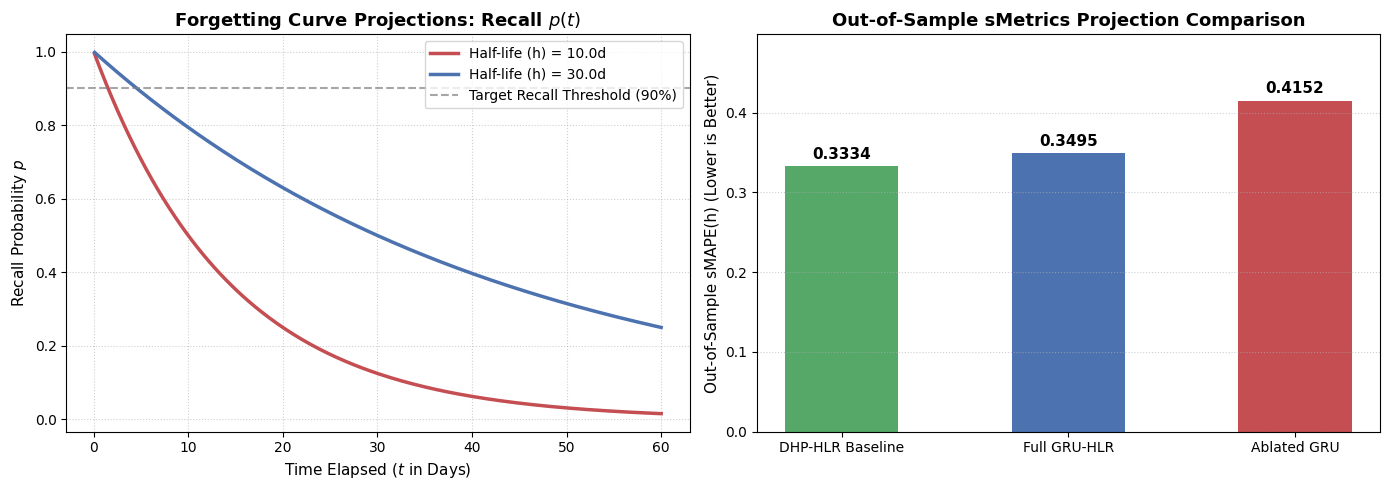

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

print("Generating Model Projections...")

# 1. Forgetting Curve Projections: Recall Probability p(t) over Time (Days)
t_days = np.linspace(0.1, 60, 200)
# Example starting half-life h = 10 days vs h = 30 days
h_short = 10.0
h_long = 30.0

p_short = np.power(2.0, -t_days / h_short)
p_long = np.power(2.0, -t_days / h_long)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot A: Forgetting Curves (Decay Projection)
axes[0].plot(t_days, p_short, label=f'Half-life (h) = {h_short}d', color='#C44E52', linewidth=2.5)
axes[0].plot(t_days, p_long, label=f'Half-life (h) = {h_long}d', color='#4C72B0', linewidth=2.5)
axes[0].axhline(0.9, color='gray', linestyle='--', alpha=0.7, label='Target Recall Threshold (90%)')
axes[0].set_title('Forgetting Curve Projections: Recall $p(t)$', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Time Elapsed ($t$ in Days)', fontsize=11)
axes[0].set_ylabel('Recall Probability $p$', fontsize=11)
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(loc='upper right')

# Plot B: GRU-HLR vs Baseline Error Projection (Model Comparison)
models = ['DHP-HLR Baseline', 'Full GRU-HLR', 'Ablated GRU']
test_smapes = [smape_h, test_smape_full, test_smape_abl]

bars = axes[1].bar(models, test_smapes, color=['#55A868', '#4C72B0', '#C44E52'], width=0.5)
axes[1].set_title('Out-of-Sample sMetrics Projection Comparison', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Out-of-Sample sMAPE(h) (Lower is Better)', fontsize=11)
axes[1].set_ylim(0, max(test_smapes) * 1.2)
axes[1].grid(True, axis='y', linestyle=':', alpha=0.6)

for bar in bars:
    height = bar.get_height()
    axes[1].annotate(f'{height:.4f}',
                     xy=(bar.get_x() + bar.get_width() / 2, height),
                     xytext=(0, 3),
                     textcoords="offset points",
                     ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()